# Twenty thousand board games, in plain SQL

**21,831 games with at least 30 ratings on BoardGameGeek**, a snapshot from January 2022. Board game ratings are a lesson in **how a ranking is built and how it can mislead**. The toolbox: `LAG()` and a moving average for the publishing boom, **a regression computed from sums** to reverse-engineer BoardGameGeek's Bayesian average (how many dummy ratings does it add?), `RANK()` to compare the raw and the adjusted ranking, a **recursive CTE** that splits the text lists of mechanics into rows (the lists arrive as one text per game), conditional shares to find rising and falling mechanics, `NTILE()` for the long tail of ratings, and a running share for the years that made the best games.

Only games with at least 30 ratings are in the data, so recent years are thin, and a game that has just come out is there only if people have already rated it; that matters for several of the results below. Python only runs the queries and draws the charts.

In [1]:
import os
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB_PATH = Path(os.environ.get("BOARDGAMES_DB", "boardgames.db"))
BLUE, AMBER, GREY, RED, GREEN = "#2b6cb0", "#e8a33d", "#a0aec0", "#c0392b", "#68a357"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

con = sqlite3.connect(DB_PATH)


def q(sql):
    """Run a query and return the result as a DataFrame."""
    return pd.read_sql_query(sql, con)

## 0. What is in the database?

In [2]:
tables = q("SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type DESC, name")
tables["rows"] = [con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0] for t in tables.name]
tables

,name,type,rows
0,game_categories,view,56632
1,game_designers,view,28984
2,game_mechanics,view,62901
3,games,table,21831


## 1. The publishing boom

Games per publication year, with a five-year moving average from a window frame and the year-on-year growth from `LAG()`. Games that have fewer than 30 ratings are not in the data, so the most recent years look smaller than they are.

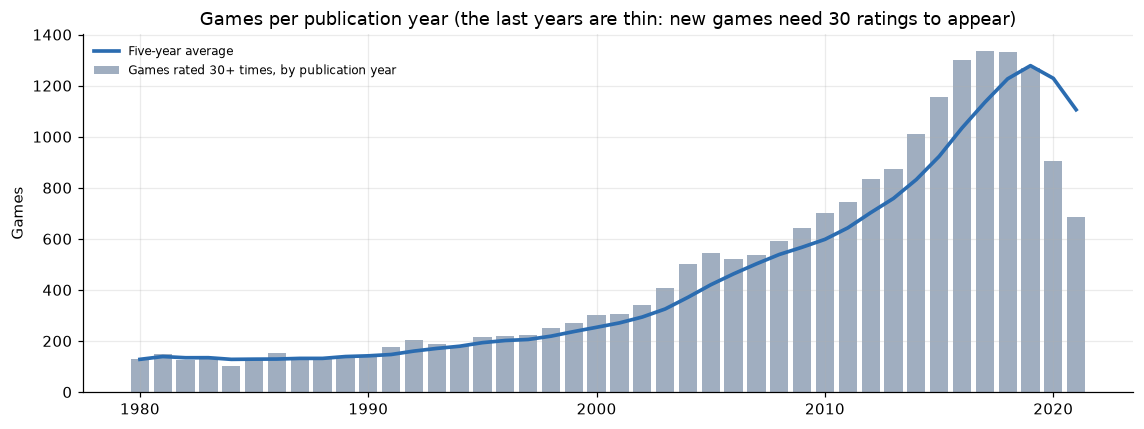

,year,games,games_5yr_avg,growth_pct
0,1980,128,128.0,NaN
10,1990,146,141.8,5.8
20,2000,300,253.6,10.7
30,2010,700,598.0,9.0
37,2017,1335,1134.6,2.6
39,2019,1269,1278.4,-4.8
41,2021,686,1105.8,-24.3


In [3]:
boom = q("""
WITH y AS (
    SELECT year, COUNT(*) AS games FROM games WHERE year BETWEEN 1980 AND 2021 GROUP BY year
)
SELECT year, games,
       ROUND(AVG(games) OVER (ORDER BY year ROWS BETWEEN 4 PRECEDING AND CURRENT ROW), 1)       AS games_5yr_avg,
       ROUND(100.0 * (games - LAG(games) OVER (ORDER BY year)) / LAG(games) OVER (ORDER BY year), 1) AS growth_pct
FROM y
ORDER BY year
""")

fig, ax = plt.subplots(figsize=(10.5, 4))
ax.bar(boom.year, boom.games, color=GREY, label="Games rated 30+ times, by publication year")
ax.plot(boom.year, boom.games_5yr_avg, color=BLUE, lw=2.4, label="Five-year average")
ax.set_ylabel("Games")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Games per publication year (the last years are thin: new games need 30 ratings to appear)")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

boom[boom.year.isin([1980, 1990, 2000, 2010, 2017, 2019, 2021])]

## 2. Do newer games get better ratings?

The average rating, BoardGameGeek's Bayesian average and the average number of ratings per game, by publication year. If games really got better, both averages should rise.

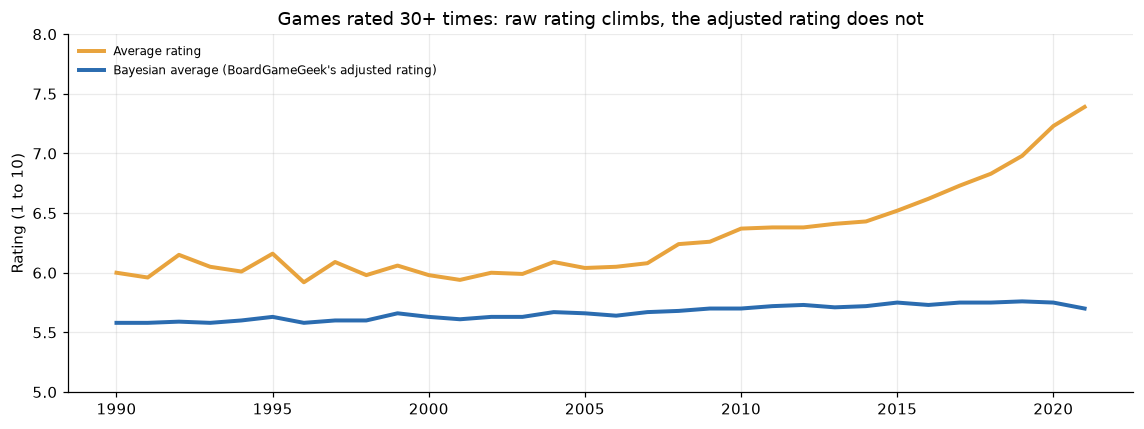

,year,games,avg_rating,avg_bayes_rating,ratings_per_game,pct_rated_7_plus
0,1990,146,6.00,5.58,325,13.7
10,2000,300,5.98,5.63,1294,14.0
20,2010,700,6.37,5.70,1028,22.6
25,2015,1154,6.52,5.75,1171,25.8
28,2018,1333,6.83,5.75,772,41.1
29,2019,1269,6.98,5.76,671,48.9
30,2020,906,7.23,5.75,462,65.5
31,2021,686,7.39,5.70,268,73.5


In [4]:
creep = q("""
SELECT year,
       COUNT(*)                                       AS games,
       ROUND(AVG(avg_rating), 2)                      AS avg_rating,
       ROUND(AVG(bayes_rating), 2)                    AS avg_bayes_rating,
       CAST(ROUND(AVG(users_rated)) AS INT)             AS ratings_per_game,
       ROUND(100.0 * AVG(avg_rating >= 7.0), 1)       AS pct_rated_7_plus
FROM games
WHERE year BETWEEN 1990 AND 2021
GROUP BY year
ORDER BY year
""")

fig, ax = plt.subplots(figsize=(10.5, 4))
ax.plot(creep.year, creep.avg_rating, color=AMBER, lw=2.6, label="Average rating")
ax.plot(creep.year, creep.avg_bayes_rating, color=BLUE, lw=2.6, label="Bayesian average (BoardGameGeek's adjusted rating)")
ax.set_ylabel("Rating (1 to 10)")
ax.set_ylim(5, 8)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Games rated 30+ times: raw rating climbs, the adjusted rating does not")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

creep[creep.year.isin([1990, 2000, 2010, 2015, 2018, 2019, 2020, 2021])]

## 3. Reverse-engineering the Bayesian average

BoardGameGeek ranks games by a Bayesian average, which pulls a rating towards a common mean by adding dummy ratings: `bayes = (n * average + k * m) / (n + k)`, with `n` real ratings and `k` dummy ones at the mean `m`. Rearranged, `n * (bayes - average) = k * m - k * bayes`, a straight line in `bayes`, so a **least-squares fit computed from sums** in SQL (`SUM(x)`, `SUM(x*y)` and so on, no library) gives `k` as the negative slope and `m` from the intercept. A recursive CTE then generates a series of averages, and the formula solved for `n` shows how many ratings a game needs to reach a Bayesian average of 7.0.

In [5]:
bayes = q("""
WITH RECURSIVE p AS (
    SELECT bayes_rating AS x, users_rated * (bayes_rating - avg_rating) AS y FROM games WHERE bayes_rating > 0
),
s AS (
    SELECT COUNT(*) AS n, SUM(x) AS sx, SUM(y) AS sy, SUM(x * x) AS sxx, SUM(x * y) AS sxy, SUM(y * y) AS syy FROM p
),
fit AS (
    SELECT n, sx, sy, (n * sxy - sx * sy) / (n * sxx - sx * sx)                                       AS slope,
           (n * sxy - sx * sy) / SQRT((n * sxx - sx * sx) * (n * syy - sy * sy))                     AS r
    FROM s
),
est AS (
    SELECT -slope AS k, ((sy - slope * sx) / n) / -slope AS m, r * r AS r2 FROM fit
),
series(avg_rating) AS (
    SELECT 7.25 UNION ALL SELECT avg_rating + 0.25 FROM series WHERE avg_rating < 9.0
)
SELECT CAST(ROUND(e.k) AS INT)                             AS dummy_ratings,
       ROUND(e.m, 2)                                       AS dummy_rating_mean,
       ROUND(e.r2, 2)                                      AS r_squared,
       s.avg_rating,
       CAST(ROUND(e.k * (7.0 - e.m) / (s.avg_rating - 7.0)) AS INT) AS ratings_needed_for_bayes_7
FROM est e
CROSS JOIN series s
ORDER BY s.avg_rating
""")

bayes

,dummy_ratings,dummy_rating_mean,r_squared,avg_rating,ratings_needed_for_bayes_7
0,2048,5.5,0.91,7.25,12258
1,2048,5.5,0.91,7.50,6129
2,2048,5.5,0.91,7.75,4086
3,2048,5.5,0.91,8.00,3064
4,2048,5.5,0.91,8.25,2452
5,2048,5.5,0.91,8.50,2043
6,2048,5.5,0.91,8.75,1751
7,2048,5.5,0.91,9.00,1532


## 4. One-vote wonders: places lost between the raw and the adjusted ranking

Two `RANK()` windows, one by the raw average and one by the Bayesian average, put the same games side by side. Among the 100 best by raw average, the ones that fall furthest are games with few ratings.

In [6]:
movers = q("""
WITH r AS (
    SELECT name, year, avg_rating, bayes_rating, users_rated,
           RANK() OVER (ORDER BY avg_rating DESC)   AS rank_raw,
           RANK() OVER (ORDER BY bayes_rating DESC) AS rank_bayes
    FROM games
)
SELECT name, year, avg_rating, users_rated, rank_raw, rank_bayes, rank_bayes - rank_raw AS places_lost
FROM r
WHERE rank_raw <= 100
ORDER BY places_lost DESC
LIMIT 8
""")

movers.assign(year=movers.year.astype('Int64'))

,name,year,avg_rating,users_rated,rank_raw,rank_bayes,places_lost
0,Sheep in Disguise,2022,8.86,32,47,21831,21784
1,TerroriXico,2018,9.43,70,3,17465,17462
2,Animator vs Animation,2018,9.06,48,19,17465,17446
3,Feuding Foodies,2021,9.00,40,28,17316,17288
4,War Titans: Invaders Must Die!,<NA>,9.24,58,9,16984,16975
5,Thug Life the Game,<NA>,9.07,49,18,16824,16806
6,NEXUM: Galaxy,2021,8.72,36,94,16638,16544
7,Ciudad de Cartón,2017,8.72,37,94,16275,16181


## 5. From a text to rows: a recursive split

Each game's mechanics arrive as one text, for example `Action Points|Cooperative Game|Hand Management`. A recursive CTE peels one item off the front of the text at each step (`substr` and `instr`) until nothing is left. `build_db.py` uses the same CTE to create the views `game_mechanics`, `game_categories` and `game_designers`; here it runs on one game, Pandemic.

In [7]:
split_demo = q("""
WITH RECURSIVE split(item, rest) AS (
    SELECT '', mechanics || '|' FROM games WHERE game_id = 30549
    UNION ALL
    SELECT substr(rest, 1, instr(rest, '|') - 1), substr(rest, instr(rest, '|') + 1)
    FROM split
    WHERE rest <> ''
)
SELECT item AS mechanic FROM split WHERE item <> ''
""")

split_demo

,mechanic
0,Action Points
1,Cooperative Game
2,Hand Management
3,Point to Point Movement
4,Set Collection
5,Trading
6,Variable Player Powers


## 6. Which mechanics go with the best-rated games?

The view `game_mechanics` joined to the games: how many games use each mechanic, their average rating and the share that is in the all-time top 1,000. Mechanics with at least 500 games.

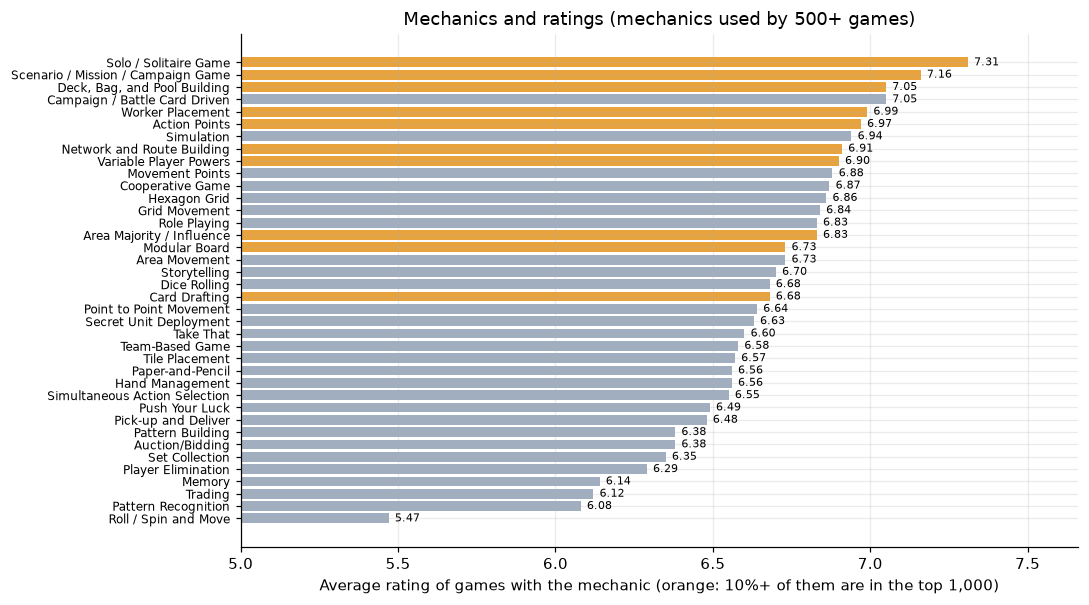

,mechanic,games,avg_rating,pct_in_top1000,avg_year
0,Solo / Solitaire Game,992,7.31,18.8,2016
1,Scenario / Mission / Campaign Game,513,7.16,10.7,2001
2,"Deck, Bag, and Pool Building",760,7.05,13.6,2016
3,Campaign / Battle Card Driven,567,7.05,9.2,2011
4,Worker Placement,775,6.99,17.8,2016
5,Action Points,1173,6.97,10.4,2011
6,Simulation,2099,6.94,3.0,1999
7,Network and Route Building,567,6.91,12.3,2011
8,Variable Player Powers,2719,6.90,12.1,2012
9,Movement Points,506,6.88,4.7,1995


In [8]:
mechanics = q("""
SELECT m.mechanic,
       COUNT(*)                                       AS games,
       ROUND(AVG(g.avg_rating), 2)                    AS avg_rating,
       ROUND(100.0 * AVG(g.rank <= 1000), 1)          AS pct_in_top1000,
       CAST(ROUND(AVG(g.year)) AS INT)                  AS avg_year
FROM game_mechanics m
JOIN games g USING (game_id)
GROUP BY m.mechanic
HAVING COUNT(*) >= 500
ORDER BY avg_rating DESC
""")

d = mechanics.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(d.mechanic, d.avg_rating, color=[AMBER if p >= 10 else GREY for p in d.pct_in_top1000])
for y, v in enumerate(d.avg_rating):
    ax.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=7.5)
ax.set_xlim(5, d.avg_rating.max() + 0.35)
ax.set_xlabel("Average rating of games with the mechanic (orange: 10%+ of them are in the top 1,000)")
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Mechanics and ratings (mechanics used by 500+ games)")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

mechanics.head(10)

## 7. Rising and falling mechanics

Each mechanic's share of all games published in 2000-2009 against its share in 2015-2021, and their ratio. A conditional sum per period does the pivot; a one-row CTE holds the period totals.

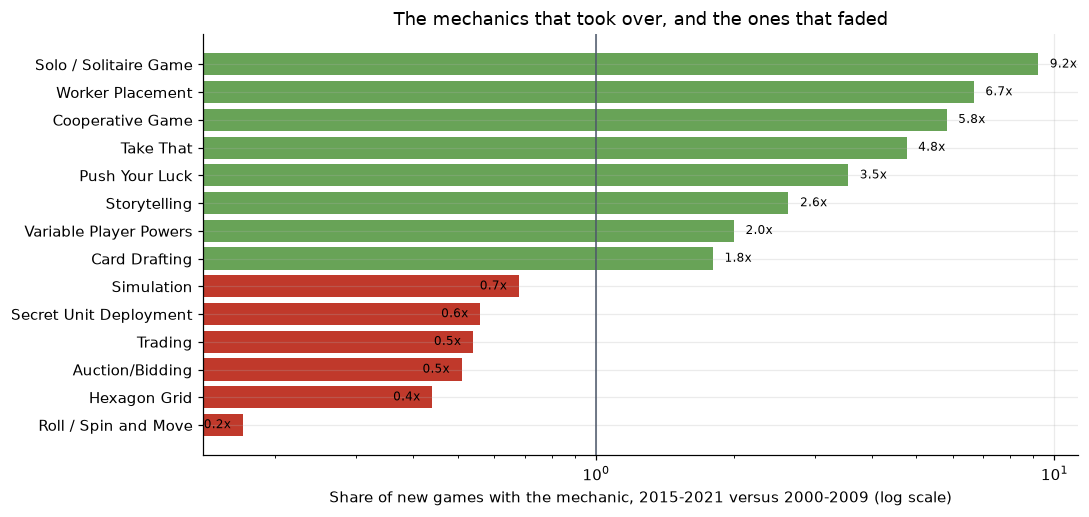

,mechanic,games_2000_09,games_2015_21,share_2000_09_pct,share_2015_21_pct,growth_x
0,Solo / Solitaire Game,44,740,1.1,9.8,9.22
1,Worker Placement,42,511,1.0,6.8,6.67
2,Cooperative Game,106,1125,2.6,14.9,5.82
3,Take That,88,763,2.1,10.1,4.76
4,Push Your Luck,88,570,2.1,7.5,3.55
5,Storytelling,63,302,1.5,4.0,2.63
6,Variable Player Powers,403,1469,9.7,19.4,2.00
7,Card Drafting,301,986,7.3,13.0,1.80


In [9]:
trends = q("""
WITH tot AS (
    SELECT SUM(year BETWEEN 2000 AND 2009) AS early, SUM(year BETWEEN 2015 AND 2021) AS late
    FROM games WHERE mechanics IS NOT NULL
),
m AS (
    SELECT mechanic, SUM(year BETWEEN 2000 AND 2009) AS early, SUM(year BETWEEN 2015 AND 2021) AS late
    FROM game_mechanics
    JOIN games USING (game_id)
    GROUP BY mechanic
)
SELECT m.mechanic, m.early AS games_2000_09, m.late AS games_2015_21,
       ROUND(100.0 * m.early / t.early, 1)                         AS share_2000_09_pct,
       ROUND(100.0 * m.late / t.late, 1)                           AS share_2015_21_pct,
       ROUND((1.0 * m.late / t.late) / (1.0 * m.early / t.early), 2) AS growth_x
FROM m CROSS JOIN tot t
WHERE m.early >= 40 AND m.late >= 100
ORDER BY growth_x DESC
""")

d = pd.concat([trends.head(8), trends.tail(6)]).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(d.mechanic, d.growth_x, color=[GREEN if g > 1 else RED for g in d.growth_x])
ax.set_xscale("log")
ax.axvline(1, color="#4a5568", lw=1)
for y, v in enumerate(d.growth_x):
    ax.text(v * (1.06 if v > 1 else 0.94), y, f"{v:.1f}x", va="center", ha="left" if v > 1 else "right", fontsize=8)
ax.set_xlabel("Share of new games with the mechanic, 2015-2021 versus 2000-2009 (log scale)")
ax.set_title("The mechanics that took over, and the ones that faded")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

trends.head(8)

## 8. Solo and cooperative games by year

Two conditional averages by publication year: the share of games that can be played alone (minimum players of 1) and the share of cooperative games (a `LIKE` on the mechanics text).

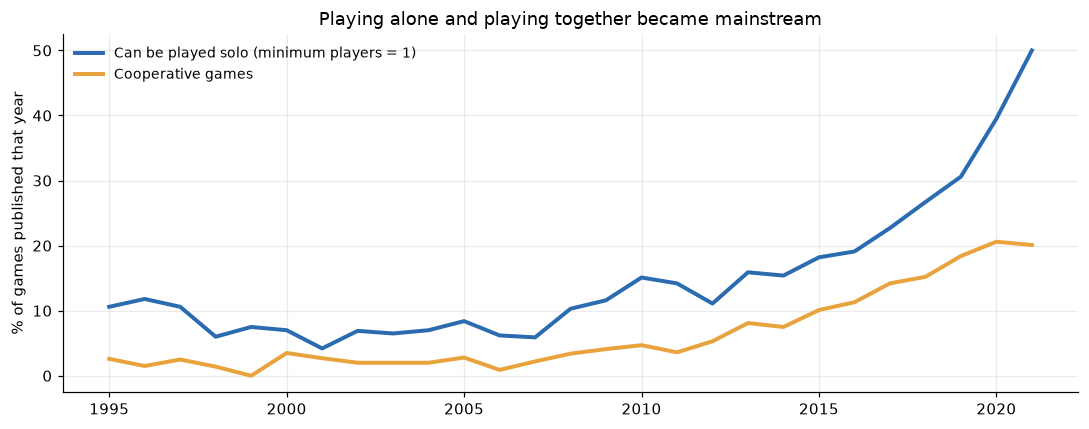

,year,games,solo_capable_pct,cooperative_pct
0,1995,190,10.6,2.6
5,2000,258,7.0,3.5
10,2005,467,8.4,2.8
15,2010,654,15.1,4.7
20,2015,1085,18.2,10.1
24,2019,1205,30.6,18.4
26,2021,667,50.0,20.1


In [10]:
solo_coop = q("""
SELECT year, COUNT(*) AS games,
       ROUND(100.0 * AVG(min_players = 1), 1)                          AS solo_capable_pct,
       ROUND(100.0 * AVG(mechanics LIKE '%Cooperative Game%'), 1)      AS cooperative_pct
FROM games
WHERE year BETWEEN 1995 AND 2021 AND mechanics IS NOT NULL
GROUP BY year
ORDER BY year
""")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(solo_coop.year, solo_coop.solo_capable_pct, color=BLUE, lw=2.6, label="Can be played solo (minimum players = 1)")
ax.plot(solo_coop.year, solo_coop.cooperative_pct, color=AMBER, lw=2.6, label="Cooperative games")
ax.set_ylabel("% of games published that year")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Playing alone and playing together became mainstream")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

solo_coop[solo_coop.year.isin([1995, 2000, 2005, 2010, 2015, 2019, 2021])]

## 9. Designers with the best games

The view `game_designers` joined to the games. `ROW_NUMBER()` per designer picks the best-ranked game, and an aggregate keeps designers with at least six games. Placeholder names such as `(Uncredited)` are left out.

In [11]:
designers = q("""
WITH d AS (
    SELECT s.designer, g.name, g.rank, g.bayes_rating, g.users_rated,
           ROW_NUMBER() OVER (PARTITION BY s.designer ORDER BY g.rank) AS rn
    FROM game_designers s
    JOIN games g USING (game_id)
    WHERE s.designer NOT LIKE '(%'
),
a AS (
    SELECT designer, COUNT(*) AS games, ROUND(AVG(bayes_rating), 2) AS avg_bayes_rating, SUM(rank <= 500) AS games_in_top500, SUM(users_rated) AS ratings
    FROM d GROUP BY designer HAVING COUNT(*) >= 6
)
SELECT a.designer, a.games, a.avg_bayes_rating, a.games_in_top500, a.ratings,
       (SELECT name FROM d WHERE d.designer = a.designer AND rn = 1) AS best_game
FROM a
ORDER BY a.avg_bayes_rating DESC
LIMIT 10
""")

designers

,designer,games,avg_bayes_rating,games_in_top500,ratings,best_game
0,Jamey Stegmaier,8,7.15,6,152042,Scythe
1,Vital Lacerda,13,6.92,8,57917,On Mars
2,Mac Gerdts,11,6.84,5,71858,Concordia
3,Nikki Valens,6,6.82,3,71426,Mansions of Madness: Second Edition
4,Corey Konieczka,27,6.81,11,248522,Twilight Imperium: Fourth Edition
5,Isaac Childres,6,6.76,2,68711,Gloomhaven
6,Jason Matthews,7,6.72,2,60443,Twilight Struggle
7,Nate French,10,6.72,3,88153,Arkham Horror: The Card Game
8,Andreas Seyfarth,7,6.71,4,121184,Puerto Rico
9,Kevin Riley,7,6.70,4,23923,Aeon's End


## 10. A long tail of ratings

`NTILE(100)` cuts the games, ordered by number of ratings, into hundred equal groups, and a running `SUM()` over the groups gives the cumulative share of all ratings that the most-rated games hold.

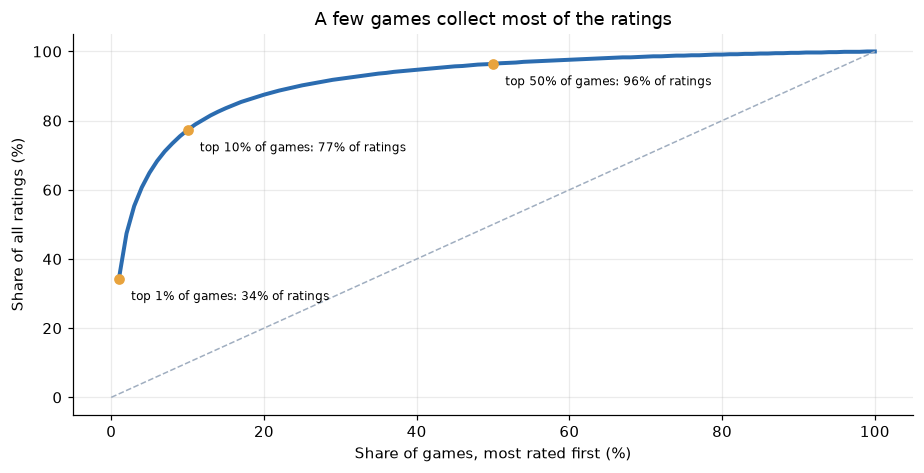

,top_percent_of_games,games,ratings,most_ratings,cumulative_pct_of_ratings
0,1,219,6489667,108975,34.3
4,5,219,791808,4060,64.9
9,10,219,340839,1650,77.3
24,25,219,87971,414,90.2
49,50,218,26969,126,96.4


In [12]:
tail = q("""
WITH n AS (
    SELECT users_rated, NTILE(100) OVER (ORDER BY users_rated DESC) AS pct FROM games
)
SELECT pct AS top_percent_of_games, COUNT(*) AS games, SUM(users_rated) AS ratings, MAX(users_rated) AS most_ratings,
       ROUND(100.0 * SUM(SUM(users_rated)) OVER (ORDER BY pct) / SUM(SUM(users_rated)) OVER (), 1) AS cumulative_pct_of_ratings
FROM n
GROUP BY pct
ORDER BY pct
""")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(tail.top_percent_of_games, tail.cumulative_pct_of_ratings, color=BLUE, lw=2.6)
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1)
for p in (1, 10, 50):
    r = tail[tail.top_percent_of_games == p].iloc[0]
    ax.scatter([p], [r.cumulative_pct_of_ratings], color=AMBER, zorder=3)
    ax.annotate(f"top {p}% of games: {r.cumulative_pct_of_ratings:.0f}% of ratings", (p, r.cumulative_pct_of_ratings), xytext=(8, -14), textcoords="offset points", fontsize=8)
ax.set_xlabel("Share of games, most rated first (%)")
ax.set_ylabel("Share of all ratings (%)")
ax.set_title("A few games collect most of the ratings")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

tail[tail.top_percent_of_games.isin([1, 5, 10, 25, 50])]

## 11. Which years made the best games?

Counting the games of the all-time top 500 by publication year, with a running share from a window `SUM()`.

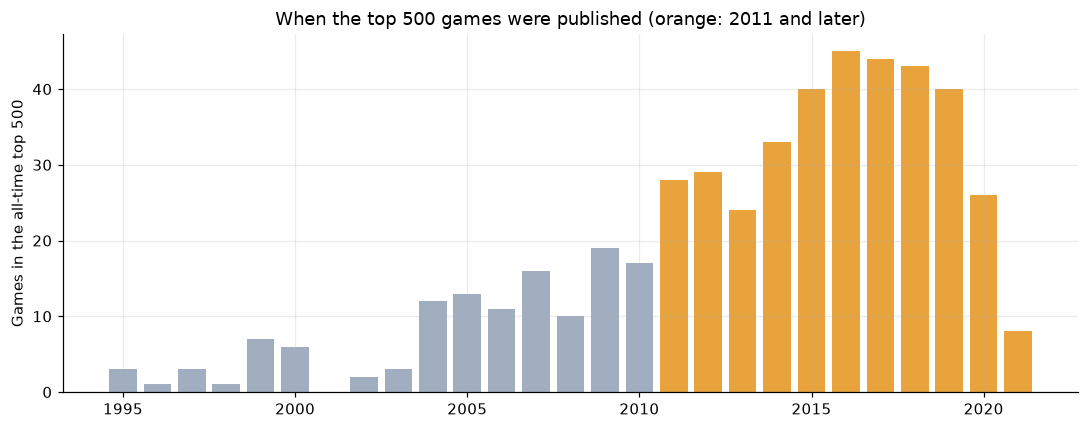

,year,games_in_top500,cumulative_pct
24,2008,10,20.6
25,2009,19,24.4
26,2010,17,27.9
27,2011,28,33.5
28,2012,29,39.3
29,2013,24,44.1
30,2014,33,50.7
31,2015,40,58.7
32,2016,45,67.7
33,2017,44,76.6


In [13]:
best_years = q("""
SELECT year, COUNT(*) AS games_in_top500,
       ROUND(100.0 * SUM(COUNT(*)) OVER (ORDER BY year) / SUM(COUNT(*)) OVER (), 1) AS cumulative_pct
FROM games
WHERE rank <= 500 AND year IS NOT NULL
GROUP BY year
ORDER BY year
""")

d = best_years[best_years.year >= 1995]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(d.year, d.games_in_top500, color=[AMBER if y >= 2011 else GREY for y in d.year])
ax.set_ylabel("Games in the all-time top 500")
ax.set_title("When the top 500 games were published (orange: 2011 and later)")
fig.tight_layout()
plt.show()  # use plt.savefig(...) to save instead

best_years[best_years.year >= 2008]

## What the queries say

- **The hobby exploded.** Games rated 30 or more times by publication year went from 128 in 1980 to 300 in 2000, 700 in 2010 and a peak of 1,335 in 2017. The five-year average peaked at 1,278 in 2019. The 24% drop in 2021 is not a bust: new games need 30 ratings to enter the data, so the latest years are always thin.
- **New games are rated higher, but the adjusted rating does not move.** The average rating of games published in a year rose from 6.00 (1990) and 5.98 (2000) to 6.37 (2010), 6.83 (2018) and 7.39 (2021), and the share rated 7.0 or more from 13.7% (1990) to 48.9% (2019) and 73.5% (2021). BoardGameGeek's Bayesian average, in the same years, went from 5.58 to 5.76 in 2019 and was 5.70 in 2021. At the same time the average number of ratings per game fell from 1,294 (2000) to 268 (2021). A game that has just come out gets into the data only if enough people rated it, and its first raters are enthusiasts, so the climb says more about selection than about better games.
- **The Bayesian average adds about 2,000 imaginary ratings.** A least-squares line computed from sums in plain SQL gives 2,048 dummy ratings at a mean of 5.50 (R-squared 0.91; not exact, because the two ratings are rounded and were taken at slightly different times). A game with an average of 8.0 needs about 3,064 real ratings to reach a Bayesian average of 7.0, one with 7.25 needs 12,258 and one with 9.0 needs 1,532. The median game has only 122 ratings, so its Bayesian average sits at about 5.5 whatever its raw average.
- **One-vote wonders vanish from the ranking.** TerroriXico has an average of 9.43 from 70 ratings, third by raw average and 17,465th by Bayesian average; Sheep in Disguise (8.86 from 32 ratings) falls from 47th to last. At the top of the Bayesian ranking is Gloomhaven (8.51 from 47,827 ratings), only 85th by raw average.
- **The lists split cleanly with a recursive CTE.** Pandemic's mechanics text becomes seven rows. The three views built with the same CTE hold 62,901 mechanic, 56,632 category and 28,984 designer links.
- **Some mechanics go with highly rated games, but part of that is newness.** Among the 38 mechanics used by 500 or more games, Solo / Solitaire has the best average rating (7.31, with 18.8% of its 992 games in the top 1,000), followed by Scenario / Campaign games (7.16) and Deck, Bag and Pool Building (7.05); Worker Placement is at 6.99 with 17.8% of its games in the top 1,000. Roll / Spin and Move is at the bottom with 5.47. The solo and deck-building games are newer on average (2016) than, say, Simulation (1999), so the newness effect above is mixed into these figures.
- **Solo, worker placement and cooperative games took over; roll-and-move faded.** The share of new games with the Solo mechanic went from 1.1% (2000-09) to 9.8% (2015-21), 9.2 times more; Worker Placement from 1.0% to 6.8% (6.7 times), Cooperative from 2.6% to 14.9% (5.8 times), Take That 4.8 times, Push Your Luck 3.6 times. Roll / Spin and Move fell from 10.2% to 1.7% (0.17 times), Hexagon Grid to 0.44 times and Auction/Bidding to 0.51 times.
- **Playing alone and together became normal.** Games that can be played solo were 7.0% of the games published in 2000, 15.1% in 2010, 30.6% in 2019 and 50.0% in 2021; cooperative games went from 3.5% to 4.7% to 18.4% to 20.1%.
- **A few designers stand out.** Among designers with at least six games, Jamey Stegmaier has the highest average Bayesian rating (7.15, six of his eight games in the top 500, best game Scythe), then Vital Lacerda (6.92, eight of 13 in the top 500, On Mars) and Mac Gerdts (6.84, Concordia). Corey Konieczka has the most ratings (248,522 over 27 games).
- **The long tail is extreme.** The most-rated 1% of games (219) hold 34.3% of all ratings, the top 5% hold 64.9%, the top 10% 77.3% and the top 25% 90.2%, while the least-rated half hold 3.6%. The most-rated game has 108,975 ratings.
- **The all-time top 500 is mostly recent.** 360 of the 500 best-ranked games (72%) were published in 2011 or later, with 2016 (45 games), 2017 (44) and 2018 (43) the biggest years. Only 28% are from 2010 or earlier.

**What to be careful about.** The data is a snapshot from January 2022 and holds only games with 30 or more ratings, so recent years are thin and survivors. The raters are BoardGameGeek members, a hobbyist crowd, not players in general. Because the Bayesian average pulls everything towards 5.5, a new game cannot reach the top ranks until thousands of people have rated it, which also tilts the top 500 towards games that have had time to collect ratings; yet the ranking is mostly recent games, a sign of how fast the hobby's audience grew. The mechanic of a game is the one the community tagged, and several can apply, so the shares above do not add up to 100%.